In [223]:
# Dataset: ทำนายคนเป็นโรคเบาหวาน [https://www.kaggle.com/datasets/akshaydattatraykhare/diabetes-dataset]
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score


train_origin = pd.read_csv("./d1/train.csv")
val_origin = pd.read_csv('./d1/val.csv')
test_origin = pd.read_csv("./d1/test.csv")


train_df = train_origin.copy()
val_df = val_origin.copy()
test_df = test_origin.copy()




In [224]:
train_df

,filename,question,answer
0,ba447400-d7ba-4095-ab40-3d509569d96b.jpg,How many buildings are in this image?,6
1,ba447400-d7ba-4095-ab40-3d509569d96b.jpg,What is the building density in this image?,high
2,ba447400-d7ba-4095-ab40-3d509569d96b.jpg,What proportion of the image shows flood damage?,0.419673
3,41f69fba-f643-4965-aa72-0865ef08f162.jpg,How many buildings are in this image?,0
4,41f69fba-f643-4965-aa72-0865ef08f162.jpg,What is the building density in this image?,no_building
...,...,...,...
5746,80988fbe-1ff5-4abc-a4cf-d71421e45dd4.jpg,What is the building density in this image?,no_building
5747,80988fbe-1ff5-4abc-a4cf-d71421e45dd4.jpg,What proportion of the image shows flood damage?,0.0
5748,3db7ed87-0591-4d6f-9ce3-17c4b6ba1458.jpg,How many buildings are in this image?,0
5749,3db7ed87-0591-4d6f-9ce3-17c4b6ba1458.jpg,What is the building density in this image?,no_building


In [225]:
test_df.isnull().sum()

filename       0
question       0
answer      1917
dtype: int64

In [226]:
val_df.isnull().sum()

filename    0
question    0
answer      0
dtype: int64

In [227]:
train_df["question"].unique()

<StringArray>
[           'How many buildings are in this image?',
      'What is the building density in this image?',
 'What proportion of the image shows flood damage?']
Length: 3, dtype: str

In [228]:
import PIL


path = "./d1/images/" + train_df["filename"][5]
image = PIL.Image.open(path)


# grayscale = PIL.ImageOps.grayscale(image)
# grayscale.show()

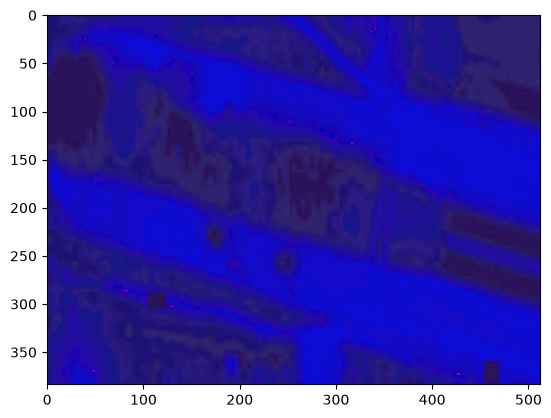

In [229]:
import cv2 as cv

image = cv.imread(path)


hsv_image = cv.cvtColor(image, cv.COLOR_BGR2HSV)

plt.imshow(hsv_image)

In [230]:
# EDA and transform the answer
# Manual mapping
import seaborn as sns
questions = train_df["question"].unique().tolist()

# train_df.loc[train_df["question"] == questions[0], "answer"].value_counts().plot(kind="barh")
# plt.show()
# train_df.loc[train_df["question"] == questions[1], "answer"].value_counts().plot(kind="barh")
# plt.show()
# print(train_df.loc[train_df["question"] == questions[2], "answer"].astype(int))

# Preprocessing part change types of the 
print(train_df.info())
print(val_df.info())
print(test_df.info())



<class 'pandas.DataFrame'>
RangeIndex: 5751 entries, 0 to 5750
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   filename  5751 non-null   str  
 1   question  5751 non-null   str  
 2   answer    5751 non-null   str  
dtypes: str(3)
memory usage: 134.9 KB
None
<class 'pandas.DataFrame'>
RangeIndex: 1917 entries, 0 to 1916
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   filename  1917 non-null   str  
 1   question  1917 non-null   str  
 2   answer    1917 non-null   str  
dtypes: str(3)
memory usage: 45.1 KB
None
<class 'pandas.DataFrame'>
RangeIndex: 1917 entries, 0 to 1916
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   filename  1917 non-null   str    
 1   question  1917 non-null   str    
 2   answer    0 non-null      float64
dtypes: float64(1), str(2)
memory usage: 45.1 KB
None


In [231]:
labels_dict = {filename: [] for filename in train_df["filename"].unique().tolist()}
# to store labels grouped by filename. 
# Structure: {"filename.jpg": [val0, val1, val2]}
questions = train_df["question"].unique().tolist()
# TODO: Loop through the CSV rows. 
# For each row, identify the filename and the answer.

def separate_files(df):
    
    data = df.copy()
    labels_dict = {filename: [] for filename in data["filename"].unique().tolist()}
    questions = train_df["question"].unique().tolist()
    for i in range(len(data)):
        if data.loc[i, "question"] == questions[0]:
        
            labels_dict[data.loc[i, "filename"]].append(data.loc[i, "answer"])
        if data.loc[i, "question"] == questions[1]:
        
            labels_dict[data.loc[i, "filename"]].append(data.loc[i, "answer"])
        if data.loc[i, "question"] == questions[2]:
        
            labels_dict[data.loc[i, "filename"]].append(data.loc[i, "answer"])
    return labels_dict

train_dict = separate_files(train_df)
val_dict = separate_files(val_df)
test_dict = separate_files(test_df)




In [232]:
import torch
from torch.utils.data import Dataset
import pandas as pd
from PIL import Image
import os
from torchvision import datasets, transforms

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),

])

test_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),

])

class TestDataset(Dataset):
    def __init__(self, csv_path, image_dir, question_mapping, transform=None,):
        """
        Args:
            csv_path (string): Path to the CSV file.
            image_dir (string): Directory where images are stored.
            question_mapping (dict): A dictionary mapping question text to indices.
                                     Example: {"Building count": 0, "Building density": 1, ...}
            transform ( callable, optional): Optional transform to be applied on images.
        """
        self.csv_path = csv_path
        self.image_dir = image_dir
        self.question_mapping = question_mapping
        self.transform = transform
        self.file = pd.read_csv(self.csv_path)
        self.labels_dict = {filename: [] for filename in self.file["filename"].unique().tolist()}
        self.filenames = self.file["filename"].unique().tolist()
       

    def __len__(self):
        # TODO: Return the total number of images in the dataset
        return len(self.file["filename"].unique().tolist())

    def __getitem__(self, idx):
        # TODO: Get the filename at the current index from self.filenames
        
        # TODO: Load the image from the image_dir using the filename
        # (Hint: You'll need to handle the path correctly)
        
        # TODO: Retrieve the 3 labels from the dictionary using the filename
        # Ensure they are converted to a Torch Tensor
        
        # TODO: Apply the transform to the image if provided
        
        # TODO: Return the image tensor and the labels tensor
        filename = self.filenames[idx]
        # Use os.path.join for safety
        path_file = os.path.join(self.image_dir, filename)
        
        # Use Image directly
        image = Image.open(path_file).convert("RGB")
        
       
        if self.transform is not None:
            image = self.transform(image)
        return {
            "image": image
            }
        
class FloodDamageDataset(Dataset):
    def __init__(self, csv_path, image_dir, question_mapping, transform=None, test=False):
        """
        Args:
            csv_path (string): Path to the CSV file.
            image_dir (string): Directory where images are stored.
            question_mapping (dict): A dictionary mapping question text to indices.
                                     Example: {"Building count": 0, "Building density": 1, ...}
            transform ( callable, optional): Optional transform to be applied on images.
        """
        self.csv_path = csv_path
        self.image_dir = image_dir
        self.question_mapping = question_mapping
        self.transform = transform
        self.test = test
        self.file = pd.read_csv(self.csv_path)
        self.labels_dict = {filename: [] for filename in self.file["filename"].unique().tolist()}
        self.filenames = self.file["filename"].unique().tolist()
        if self.test:

    
            for i in range(len(self.file)):
                if self.file.loc[i, "question"] == self.question_mapping[0]:
                    self.labels_dict[self.file.loc[i, "filename"]].append(self.file.loc[i, "answer"])
                    
                if self.file.loc[i, "question"] == self.question_mapping[1]:
                    self.labels_dict[self.file.loc[i, "filename"]].append(self.file.loc[i, "answer"])
                    
                if self.file.loc[i, "question"] == self.question_mapping[2]:
                    self.labels_dict[self.file.loc[i, "filename"]].append(self.file.loc[i, "answer"])

    def __len__(self):
        # TODO: Return the total number of images in the dataset
        return len(self.file["filename"].unique().tolist())

    def __getitem__(self, idx):
        # TODO: Get the filename at the current index from self.filenames
        
        # TODO: Load the image from the image_dir using the filename
        # (Hint: You'll need to handle the path correctly)
        
        # TODO: Retrieve the 3 labels from the dictionary using the filename
        # Ensure they are converted to a Torch Tensor
        
        # TODO: Apply the transform to the image if provided
        
        # TODO: Return the image tensor and the labels tensor
        filename = self.filenames[idx]
        # Use os.path.join for safety
        path_file = os.path.join(self.image_dir, filename)
        
        # Use Image directly
        image = Image.open(path_file).convert("RGB")
        
        if not self.test:
            # Convert the list to a tensor
            labels = self.labels_dict[filename]
            
            labels[0] = int(labels[0])
            labels[2] = float(labels[2])
            
            
            density = 0
            if labels[1] == "no_building":
                density = 0
            elif labels[1] == "low":
                density = 1
            elif labels[1] == "moderate":
                density = 2
            elif labels[1] == "high":
                density = 3
                
            labels[1] = density 
            classification_labels = torch.tensor(labels[:2], dtype=torch.long)
            regression_labels = torch.tensor(labels[2], dtype=torch.float32)
            
        
            if self.transform is not None:
                image = self.transform(image)
       
      
        
            return {
                "image": image,
                "building_count": classification_labels[0],
                "density": classification_labels[1],
                "affected_area": regression_labels.item()
            }
        else:
            if self.transform is not None:
                image = self.transform(image)
            return {
                "image": image
            }

train_dataset = FloodDamageDataset("./d1/train.csv", "./d1/images/", questions, transform=train_transform)
val_dataset = FloodDamageDataset("./d1/val.csv", "./d1/images/", questions, transform=train_transform)
test_dataset =TestDataset("./d1/test.csv", "./d1/images/", questions, transform=test_transform)

train_dataloader = DataLoader(train_dataset, shuffle=True, batch_size=32)
val_dataloader = DataLoader(val_dataset, shuffle=False, batch_size=32)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [233]:
def multitask_loss(outputs, one_targets, two_targets, three_targets):
    one_loss = nn.MSELoss(outputs["one"], one_targets)
    two_loss = nn.CrossEntropyLoss(outputs["two"], two_targets)
    three_loss = nn.MSELoss(outputs["three"], three_targets)
    total = one_loss + two_loss + three_loss
    return {"total_loss": total, "one": one_loss, "two": two_loss, "three": three_loss}

In [234]:
class CustomLeNet5(nn.Module):
    def __init__(self, input_size=(3, 256, 256), num_classes=4):
        super(CustomLeNet5, self).__init__()
        self.extractor = nn.Sequential(
            nn.Conv2d(in_channels=input_size[0], out_channels=32, kernel_size=5, stride=1, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5, stride=1, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
        )

        self.head1 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self._get_input_size_fc1(input_size), 256), 
            nn.ReLU(), nn.Dropout(), nn.Linear(256, 128), 
            nn.ReLU(), nn.Dropout(), nn.Linear(128, 10))
        self.head2 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self._get_input_size_fc1(input_size), 256), 
            nn.ReLU(), 
            nn.Dropout(), 
            nn.Linear(256, 128), 
            nn.ReLU(), 
            nn.Dropout(), 
            nn.Linear(128, 4)
        )
        self.head3 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self._get_input_size_fc1(input_size), 256), 
            nn.ReLU(), 
            nn.Dropout(), 
            nn.Linear(256, 128), 
            nn.ReLU(), 
            nn.Dropout(), 
            nn.Linear(128, 1)
        )
        
    def _get_input_size_fc1(self, input_shape):
        with torch.no_grad():
            x = torch.zeros(1, *input_shape)
            x = self.extractor(x)
            x = torch.flatten(x, 1)
        return x.size(1)

    def forward(self, x):
        # This is the processed feature map
        shared = self.extractor(x) 
        
        # Pass 'shared' into the heads instead of 'x'
        one = self.head1(shared)
        two = self.head2(shared)
        three = self.head3(shared)
        
        out = {
            "building_count": one,
            "density": two,
            "affected_area": three
        }
        return out
   




In [235]:
from sklearn.metrics import f1_score, accuracy_score, root_mean_squared_error
def compute_score(
    y_count_true,
    y_count_pred,
    y_density_true,
    y_density_pred,
    y_area_true,
    y_area_pred,
):

    y_count_true = y_count_true.detach().cpu().numpy()
    y_count_pred = y_count_pred
    y_density_true = y_density_true.detach().cpu().numpy()
    y_density_pred = y_density_pred
    y_area_true = y_area_true.detach().cpu().numpy()
    y_area_pred = y_area_pred.detach().cpu().numpy()

    
    density_f1 = f1_score(y_density_true, y_density_pred, average="macro")
    count_acc = accuracy_score(y_count_true, y_count_pred)
    area_rmse = root_mean_squared_error(y_area_true, y_area_pred)

    score = (0.4*density_f1) + (0.4*np.log10(count_acc/0.1)) + (0.3*(1/1+np.exp(-80*(area_rmse-0.19))) * np.exp(-4 * (area_rmse-0.19)))

    return score
    


In [236]:
from tqdm import tqdm
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CustomLeNet5().to(device)

epochs = 100
loss_count = nn.CrossEntropyLoss()
loss_density = nn.CrossEntropyLoss()
loss_area = nn.MSELoss()
opt = optim.Adam(model.parameters())

best_score = -float('inf') # Initialize with a very low number
checkpoint_path = "best_model_checkpoint.pth"
for epoch in range(epochs):
    model.train()
    train_loss = []
    train_scores = []
    for batch in tqdm(train_dataloader, desc=f"Epoch: {epoch}"):
        image = batch["image"].to(device)
        count = batch["building_count"].to(device)
        density = batch["density"].to(device)
        area = batch["affected_area"].to(device).float()

        outputs = model(image)
        count_pred = outputs["building_count"]
        density_pred = outputs["density"]
        area_pred = outputs["affected_area"]
        
        opt.zero_grad()

       
        loss_1 = loss_count(count_pred, count)
        loss_2 = loss_density(density_pred, density)
        loss_3 = loss_area(area_pred, area.view(-1, 1))

        total_loss = 0.4*loss_1 + 0.4*loss_2 + 0.3*loss_3
        
        total_loss.backward()
        opt.step()

        dense_pred = torch.argmax(density_pred, dim=1).detach().cpu().numpy()
        c_pred = torch.argmax(count_pred, dim=1).detach().cpu().numpy()
        score = compute_score(count, c_pred, density, dense_pred, area, area_pred)

        train_loss.append(total_loss.item())
        train_scores.append(score)

      

    model.eval()
    val_loss = []
    val_scores = []
    with torch.no_grad():
        for batch in tqdm(val_dataloader, desc=f"Epoch: {epoch}"):
            image = batch["image"].to(device)
            count = batch["building_count"].to(device)
            density = batch["density"].to(device)
            area = batch["affected_area"].to(device).float()

            outputs = model(image)
            count_pred = outputs["building_count"]
            density_pred = outputs["density"]
            area_pred = outputs["affected_area"]
      
            loss_1 = loss_count(count_pred, count)
            loss_2 = loss_density(density_pred, density)
            loss_3 = loss_area(area_pred, area.view(-1, 1))
    
            total_loss = loss_1 + loss_2 + loss_3
            dense_pred = torch.argmax(density_pred, dim=1).detach().cpu().numpy()
            c_pred = torch.argmax(count_pred, dim=1).detach().cpu().numpy()
            score = compute_score(count, c_pred, density, dense_pred, area, area_pred)
            val_loss.append(total_loss)
            val_scores.append(score)

    current_val_score = sum(val_scores) / len(val_scores)
    if current_val_score > best_score:
        best_score = current_val_score

        torch.save(model.state_dict(), checkpoint_path)
        print(f"Save new checkpoint at {current_val_score}")
    
    if epoch % 5 == 0:
        print(f"Epoch {epoch}: Train Loss: {sum(train_loss) / len(train_loss)}")
        print(f"Val Loss: {sum(train_loss)/len(train_loss)}")
        print(f"Train Score: {sum(train_scores)/len(train_scores)}")
        print(f"Val Score: {sum(val_scores)/len(val_scores)}")

    
        
        
    

Epoch: 0:   0%|          | 0/60 [00:00<?, ?it/s]


IndexError: list index out of range

In [326]:
test_model = CustomLeNet5().to(device)
test_model.load_state_dict(torch.load(checkpoint_path, weights_only=True))

test_model.eval()

one_pred = []
two_pred = []
three_pred = []

with torch.no_grad():
    for batch in tqdm(test_dataloader):
        image = batch["image"].to(device)
        
        outputs = test_model(image)
        count_pred = outputs["building_count"]
        density_pred = outputs["density"]
        area_pred = outputs["affected_area"]

        dense_pred = torch.argmax(density_pred, dim=1).detach().cpu().numpy()
        c_pred = torch.argmax(count_pred, dim=1).detach().cpu().numpy()
       
        one_pred.extend(c_pred)
        two_pred.extend(dense_pred)
        three_pred.extend(area_pred.detach().cpu().numpy())
        
        

        
        
    


100%|██████████| 20/20 [00:02<00:00,  8.54it/s]


In [308]:
print(len(test_dataloader) * 32 * 3)
print(len(test_df))


1920
1917


In [327]:
t_pred = []

for pred in three_pred:
    t_pred.append(pred[0])


In [333]:
filenames = test_df["filename"].to_list()

submission = pd.DataFrame({
    "filename": filenames,
    "questions": test_df["question"].to_list(),
    
})

0       65fd282e-1a63-4035-abb0-e283019a845d.jpg
1       65fd282e-1a63-4035-abb0-e283019a845d.jpg
2       65fd282e-1a63-4035-abb0-e283019a845d.jpg
3       91033ea1-1e15-4a21-84b0-b16fe042a9ed.jpg
4       91033ea1-1e15-4a21-84b0-b16fe042a9ed.jpg
                          ...                   
1912    22877c4a-c10c-4418-9718-bebad9d80211.jpg
1913    22877c4a-c10c-4418-9718-bebad9d80211.jpg
1914    dd919cae-5e25-4edd-ad5d-76618312cf58.jpg
1915    dd919cae-5e25-4edd-ad5d-76618312cf58.jpg
1916    dd919cae-5e25-4edd-ad5d-76618312cf58.jpg
Name: filename, Length: 1917, dtype: str

In [332]:
for i in range(len(test)):
        if test.loc[i, "question"] == self.question_mapping[0]:
            self.labels_dict[self.file.loc[i, "filename"]].append(self.file.loc[i, "answer"])
            
        if self.file.loc[i, "question"] == self.question_mapping[1]:
            self.labels_dict[self.file.loc[i, "filename"]].append(self.file.loc[i, "answer"])
            
        if self.file.loc[i, "question"] == self.question_mapping[2]:
            self.labels_dict[self.file.loc[i, "filename"]].append(self.file.loc[i, "answer"])

NameError: name 'self' is not defined

In [369]:
import pandas as pd
import numpy as np
import torch



def save_to_csv(filenames, results, questions):
    """
    Args:
        filenames: list of strings (length N)
        results: list of 3 numpy arrays, each of length N
        questions: list of 3 strings
    """
    all_rows = []

    # Iterate through every image/file in your dataset (0 to N-1)
    for i in range(len(filenames)):
        fname = filenames[i]
        
        # For this specific image (index i), we need to grab the 
        # prediction for each of the 3 labels.
        # results[0] = all predictions for Label 1
        # results[1] = all predictions for Label 2
        # results[2] = all predictions for Label 3
        
        for j in range(3):
            # 1. Extract the prediction for the current label (j) 
            # at the current image position (i)
            pred_array = results[j][i]
            
            # 2. Get the corresponding question for this label
            current_question = questions[j]
            
            # 3. Convert the array to a standard Python number 
            # (Important: Pandas/CSV can't save raw objects like arrays)
            if isinstance(pred_array, (torch.Tensor, np.ndarray)):
                if pred_array.size == 1:
                    val = pred_array.item()
                else:
                    val = pred_array.tolist()
            else:
                val = pred_array

            # 4. Add the dictionary for this specific row
            all_rows.append({
                "filename": fname,
                "question": current_question,
                "answer": val
            })

    # Create DataFrame and Export
    df = pd.DataFrame(all_rows)
    df.to_csv('submissions.csv', index=False)
    print(f"Successfully saved {len(df)} rows to submissions.csv")

# --- HOW TO CALL IT ---
filenames = test_df["filename"].tolist()
datalist = [one_pred, two_pred, three_pred]
save_to_csv(filenames, datalist, questions)

IndexError: list index out of range

In [371]:
# Instead of calling it outside the loop, do this inside your loop:
for index, row in test_df.iterrows():
    # ... your code that generates one_pred, two_pred, three_pred ...
    
    # Use ONLY the filename for this specific row
    current_filename = row["filename"] 
    
    # Call the function with just this one filename
    # (You'll need to slightly adjust the function to handle a single string)
    save_single_row(current_filename, [one_pred, two_pred, three_pred], questions)

NameError: name 'save_single_row' is not defined

In [384]:
all_rows = [] # Create a master list outside the loop

for i in range(len(test_df["filename"].unique().tolist())):
    # ... your code that generates one_pred, two_pred, three_pred ...

    # Add all 3 results for this file to our master list
    all_rows.append({"filename": filename, "one": one_pred[index], "two": two_pred[index], "three": three_pred[index]})


# Now call the Pandas function once at the very end
df = pd.DataFrame(all_rows)
df.to_csv('submissions.csv', index=False)

IndexError: list index out of range

In [373]:
df

,filename,question,answer
0,65fd282e-1a63-4035-abb0-e283019a845d.jpg,How many buildings are in this image?,"[1, 3, 0, 2, 6, 1, 2, 3, 5, 1, 1, 2, 6, 4, 0, ..."
1,65fd282e-1a63-4035-abb0-e283019a845d.jpg,What is the building density in this image?,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,65fd282e-1a63-4035-abb0-e283019a845d.jpg,What proportion of the image shows flood damage?,"[[0.10899843], [0.16605361], [0.0971559], [0.2..."
3,65fd282e-1a63-4035-abb0-e283019a845d.jpg,How many buildings are in this image?,"[1, 3, 0, 2, 6, 1, 2, 3, 5, 1, 1, 2, 6, 4, 0, ..."
4,65fd282e-1a63-4035-abb0-e283019a845d.jpg,What is the building density in this image?,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
...,...,...,...
5746,dd919cae-5e25-4edd-ad5d-76618312cf58.jpg,What is the building density in this image?,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
5747,dd919cae-5e25-4edd-ad5d-76618312cf58.jpg,What proportion of the image shows flood damage?,"[[0.10899843], [0.16605361], [0.0971559], [0.2..."
5748,dd919cae-5e25-4edd-ad5d-76618312cf58.jpg,How many buildings are in this image?,"[1, 3, 0, 2, 6, 1, 2, 3, 5, 1, 1, 2, 6, 4, 0, ..."
5749,dd919cae-5e25-4edd-ad5d-76618312cf58.jpg,What is the building density in this image?,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
